# CALPHAD Cr–V Binary Phase Diagrams

This notebook uses `CrV-24Ton.tdb` to calculate Cr–V equilibrium phase diagrams in atomic percent (at.%). It includes full-system, high-temperature, and focused 10–25 at.% liquidus/solidus results in both composition directions.

In [1]:
from collections.abc import Callable, Iterable
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from pycalphad import Database, equilibrium
from pycalphad.mapping import BinaryStrategy, plot_binary
import pycalphad.variables as v

PHASE_AMOUNT_TOLERANCE = 1e-6
TEMPERATURE_TOLERANCE = 0.1
VACANCY_COMPONENT = "VA"

## Database and calculation settings

The focused diagrams calculate **all-phase equilibrium** using every phase from `CrV-24Ton.tdb`. Direct equilibrium boundary calculations are used for the focused plots so solidus and liquidus values are not inferred from plotted map lines.

In [2]:
DATABASE_DIRECTORY = Path("database")
database_files = sorted(DATABASE_DIRECTORY.glob("*.tdb"))
selected_database = DATABASE_DIRECTORY / "CrV-24Ton.tdb"
binary_elements = ("CR", "V")
pressure = 101325.0  # Pa

temperature_range = (300.0, 2500.0, 10.0)
equilibrium_temperature_range = (1950.0, 2200.0, 5.0)

# All phase candidates in CrV-24Ton.tdb.
all_phases = ("LIQUID", "BCC_A2", "FCC_A1", "HCP_A3")

# Cr–V (V dissolving), then V–Cr (Cr dissolving).
dissolving_elements = ("V", "CR")
focused_boundary_temperature_ranges = {
    "V": (2000.0, 2120.0, 2.0),
    "CR": (2080.0, 2170.0, 2.0),
}
focused_y_axis_ranges = {
    "V": (2020.0, 2110.0),
    "CR": (2080.0, 2160.0),
}
focused_boundary_curve_step_atomic_percent = 0.5
focused_data_point_atomic_percents = {
    "V": (*range(10, 26, 2), 25.0),
    "CR": (*range(10, 26, 2), 25.0),
}
full_atomic_fraction_range = (0.0, 1.0, 0.02)
focused_atomic_fraction_range = (0.10, 0.25, 0.005)

## Thermodynamic calculation and plotting helpers

In [3]:
def validated_components(database: Database, elements: tuple[str, str]) -> list[str]:
    database_elements = {element.upper() for element in database.elements}
    missing_elements = {element.upper() for element in elements} - database_elements
    if missing_elements:
        raise ValueError(f"Database is missing requested elements: {', '.join(sorted(missing_elements))}.")
    components = [element.upper() for element in elements]
    if VACANCY_COMPONENT in database_elements:
        components.append(VACANCY_COMPONENT)
    return components


def validate_calculation_setup(database: Database, elements: tuple[str, str], phases: tuple[str, ...]) -> list[str]:
    components = validated_components(database, elements)
    missing_phases = set(phases) - set(database.phases)
    if missing_phases:
        raise ValueError(f"Database is missing requested phases: {', '.join(sorted(missing_phases))}.")
    return components


def phase_amounts_at_composition(database: Database, components: list[str], dissolving_element: str, atomic_fraction: float, temperature: float) -> dict[str, float]:
    result = equilibrium(database, components, all_phases, {
        v.X(dissolving_element): atomic_fraction, v.T: temperature, v.P: pressure, v.N: 1,
    })
    return {str(phase).upper(): float(amount) for phase, amount in zip(result.Phase.values.ravel(), result.NP.values.ravel()) if str(phase)}


def find_transition_temperature(predicate: Callable[[dict[str, float]], bool], database: Database, components: list[str], dissolving_element: str, atomic_fraction: float, search_temperature_range: tuple[float, float, float]) -> float | None:
    temperature_minimum, temperature_maximum, temperature_step = search_temperature_range
    temperatures = np.arange(temperature_minimum, temperature_maximum + temperature_step, temperature_step)
    previous_temperature = float(temperatures[0])
    if predicate(phase_amounts_at_composition(database, components, dissolving_element, atomic_fraction, previous_temperature)):
        return previous_temperature
    for temperature in temperatures[1:]:
        temperature = float(temperature)
        if predicate(phase_amounts_at_composition(database, components, dissolving_element, atomic_fraction, temperature)):
            lower_temperature, upper_temperature = previous_temperature, temperature
            while upper_temperature - lower_temperature > TEMPERATURE_TOLERANCE:
                middle_temperature = (lower_temperature + upper_temperature) / 2
                if predicate(phase_amounts_at_composition(database, components, dissolving_element, atomic_fraction, middle_temperature)):
                    upper_temperature = middle_temperature
                else:
                    lower_temperature = middle_temperature
            return upper_temperature
        previous_temperature = temperature
    return None


def equilibrium_solidus_and_liquidus(database: Database, components: list[str], dissolving_element: str, atomic_fraction: float, search_temperature_range: tuple[float, float, float]) -> tuple[float | None, float | None, str]:
    solidus = find_transition_temperature(lambda amounts: amounts.get("LIQUID", 0.0) > PHASE_AMOUNT_TOLERANCE, database, components, dissolving_element, atomic_fraction, search_temperature_range)
    liquidus = find_transition_temperature(lambda amounts: amounts.get("LIQUID", 0.0) >= 1 - PHASE_AMOUNT_TOLERANCE, database, components, dissolving_element, atomic_fraction, search_temperature_range)
    if solidus is None:
        return None, liquidus, "not found"
    below_solidus = phase_amounts_at_composition(database, components, dissolving_element, atomic_fraction, solidus - TEMPERATURE_TOLERANCE)
    solid_phases = sorted(phase for phase, amount in below_solidus.items() if phase != "LIQUID" and amount > PHASE_AMOUNT_TOLERANCE)
    return solidus, liquidus, " + ".join(solid_phases) or "not found"


def system_label(elements: tuple[str, str], dissolving_element: str) -> str:
    solvent = next(element for element in elements if element != dissolving_element)
    return f"{solvent}–{dissolving_element} ({dissolving_element} dissolving)"


def merge_composition_set_legend(axis: Axes) -> None:
    legend = axis.get_legend()
    if legend is None:
        return
    handles, labels = [], []
    for handle, text in zip(legend.legend_handles, legend.get_texts()):
        base_phase = text.get_text().split("#", maxsplit=1)[0]
        if base_phase not in labels:
            handles.append(handle)
            labels.append(base_phase)
    axis.legend(handles=handles, labels=labels, loc="center left", bbox_to_anchor=(1, 0.5))


def plot_diagram_pair(database: Database, components: list[str], composition_range: tuple[float, float, float], diagram_temperature_range: tuple[float, float, float], description: str) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=150)
    for axis, dissolving_element in zip(axes, dissolving_elements):
        strategy = BinaryStrategy(database, components, phases=all_phases, conditions={
            v.X(dissolving_element): composition_range, v.T: diagram_temperature_range, v.P: pressure, v.N: 1,
        }, plot_kwargs={"ax": axis})
        strategy.do_map()
        plot_binary(strategy, x=v.X(dissolving_element), y=v.T, ax=axis)
        merge_composition_set_legend(axis)
        axis.set_xlim(composition_range[:2])
        axis.set_ylim(diagram_temperature_range[:2])
        axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.set_xlabel(f"Atomic Percent {dissolving_element} (at.%)")
        axis.set_ylabel("Temperature (K)")
        axis.set_title(f"{system_label(binary_elements, dissolving_element)}\n{description}")
        axis.grid(True, which="both", linestyle="--", linewidth=0.5)
    figure.tight_layout()
    plt.show()

In [4]:
def calculate_boundary_data(database: Database, components: list[str], dissolving_element: str, atomic_percents: Iterable[float]) -> pd.DataFrame:
    compositions = np.asarray(tuple(atomic_percents), dtype=float)
    fractions = compositions / 100
    if np.any(fractions < focused_atomic_fraction_range[0]) or np.any(fractions > focused_atomic_fraction_range[1]):
        raise ValueError("All focused atomic-percent values must lie within focused_atomic_fraction_range.")
    records = []
    for atomic_percent, atomic_fraction in zip(compositions, fractions):
        solidus, liquidus, solid_phases = equilibrium_solidus_and_liquidus(database, components, dissolving_element, atomic_fraction, focused_boundary_temperature_ranges[dissolving_element])
        records.append({f"{dissolving_element} (at.%)": atomic_percent, "Equilibrium solidus (K)": solidus, "Equilibrium liquidus (K)": liquidus, "Stable solid phase(s) below solidus": solid_phases})
    return pd.DataFrame(records)


def focused_curve_compositions() -> np.ndarray:
    start, end = np.asarray(focused_atomic_fraction_range[:2]) * 100
    return np.append(np.arange(start, end, focused_boundary_curve_step_atomic_percent), end)


def plot_focused_diagrams(database: Database, components: list[str]) -> None:
    for dissolving_element in dissolving_elements:
        curve_data = calculate_boundary_data(database, components, dissolving_element, focused_curve_compositions())
        boundary_data = calculate_boundary_data(database, components, dissolving_element, focused_data_point_atomic_percents[dissolving_element])
        composition_column = f"{dissolving_element} (at.%)"
        solidus_column, liquidus_column = "Equilibrium solidus (K)", "Equilibrium liquidus (K)"
        curve_x = curve_data[composition_column].to_numpy(dtype=float) / 100
        solidus_curve = pd.to_numeric(curve_data[solidus_column], errors="coerce").to_numpy(dtype=float)
        liquidus_curve = pd.to_numeric(curve_data[liquidus_column], errors="coerce").to_numpy(dtype=float)
        valid_curve = np.isfinite(curve_x) & np.isfinite(solidus_curve) & np.isfinite(liquidus_curve)
        if not valid_curve.any():
            raise ValueError(f"No equilibrium melting boundaries found for {dissolving_element}.")
        figure, axis = plt.subplots(figsize=(8, 7), dpi=150)
        axis.plot(curve_x[valid_curve], solidus_curve[valid_curve], color="#00538A", linewidth=1.4)
        axis.plot(curve_x[valid_curve], liquidus_curve[valid_curve], color="#F4C800", linewidth=1.4)
        axis.fill_between(curve_x[valid_curve], solidus_curve[valid_curve], liquidus_curve[valid_curve], color="#F4C800", alpha=0.12)
        point_x = boundary_data[composition_column].to_numpy(dtype=float) / 100
        solidus_points = pd.to_numeric(boundary_data[solidus_column], errors="coerce").to_numpy(dtype=float)
        liquidus_points = pd.to_numeric(boundary_data[liquidus_column], errors="coerce").to_numpy(dtype=float)
        axis.scatter(point_x[np.isfinite(solidus_points)], solidus_points[np.isfinite(solidus_points)], color="#00538A", edgecolor="white", linewidth=0.6, s=36, zorder=4)
        axis.scatter(point_x[np.isfinite(liquidus_points)], liquidus_points[np.isfinite(liquidus_points)], color="#F4C800", edgecolor="white", linewidth=0.6, s=36, zorder=4)
        axis.legend(handles=[Patch(color="#00538A", label="Equilibrium solidus"), Patch(color="#F4C800", label="LIQUID")], loc="upper left", bbox_to_anchor=(1.02, 1))
        axis.set_xlim(focused_atomic_fraction_range[:2])
        axis.set_ylim(focused_y_axis_ranges[dissolving_element])
        axis.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
        axis.set_xlabel(f"Atomic Percent {dissolving_element} (at.%)")
        axis.set_ylabel("Temperature (K)")
        axis.set_title(f"{system_label(binary_elements, dissolving_element)}\nEquilibrium liquidus/solidus region (10–25 at.%)")
        axis.grid(True, which="both", linestyle="--", linewidth=0.5)
        figure.tight_layout()
        plt.show()
        print(f"{system_label(binary_elements, dissolving_element)}: selected equilibrium boundary temperatures")
        display(boundary_data.round(1))

## 1. Full binary system: all phases

This view includes `LIQUID`, `BCC_A2`, `FCC_A1`, and `HCP_A3` across the complete composition range.

Database: CrV-24Ton.tdb
Components: CR, V, VA
All phases: LIQUID, BCC_A2, FCC_A1, HCP_A3


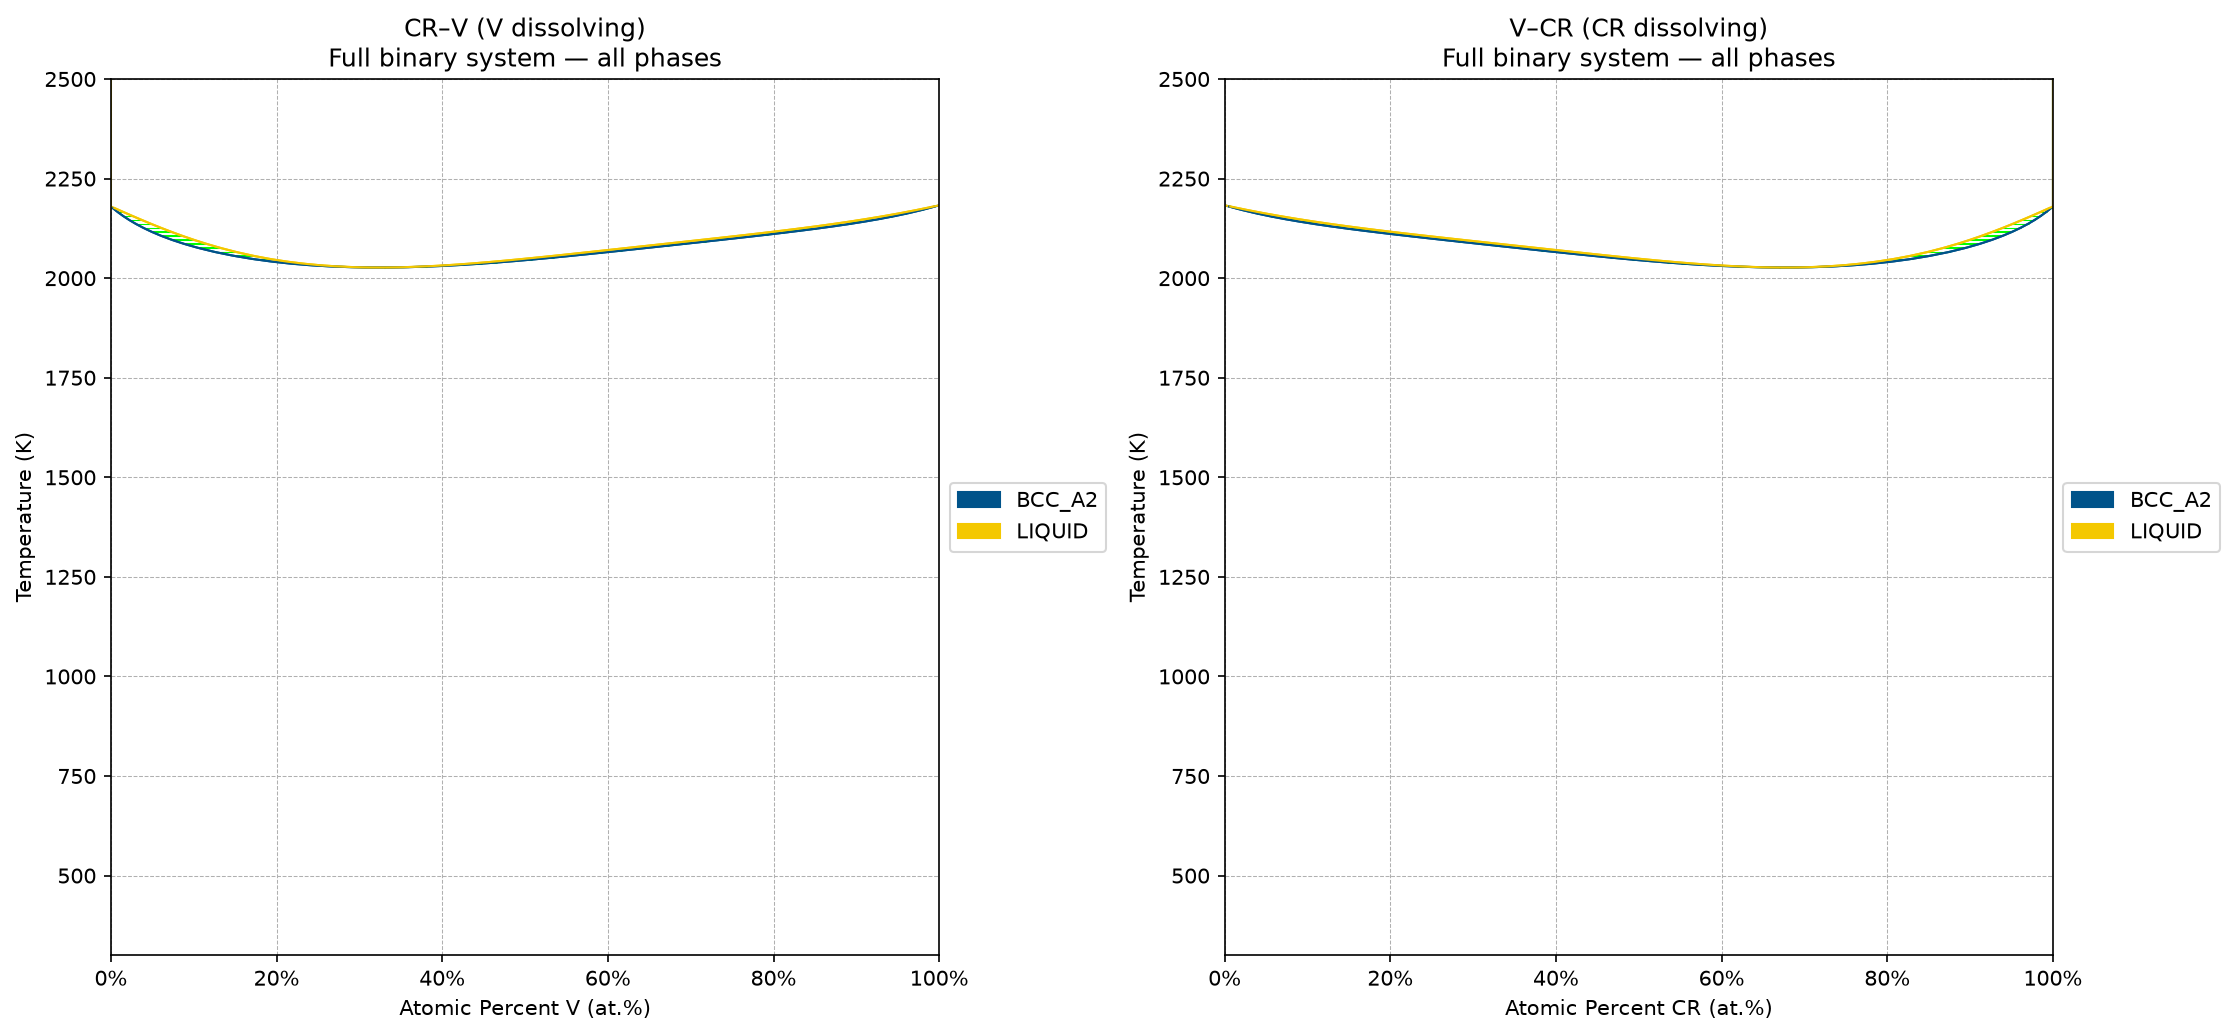

In [5]:
database = Database(selected_database)
calculation_components = validate_calculation_setup(database, binary_elements, all_phases)
print(f"Database: {selected_database.name}")
print(f"Components: {', '.join(calculation_components)}")
print(f"All phases: {', '.join(all_phases)}")
plot_diagram_pair(database, calculation_components, full_atomic_fraction_range, temperature_range, "Full binary system — all phases")

## 2. Full binary system: high-temperature equilibrium

This view isolates the melting interval while retaining all phase candidates.

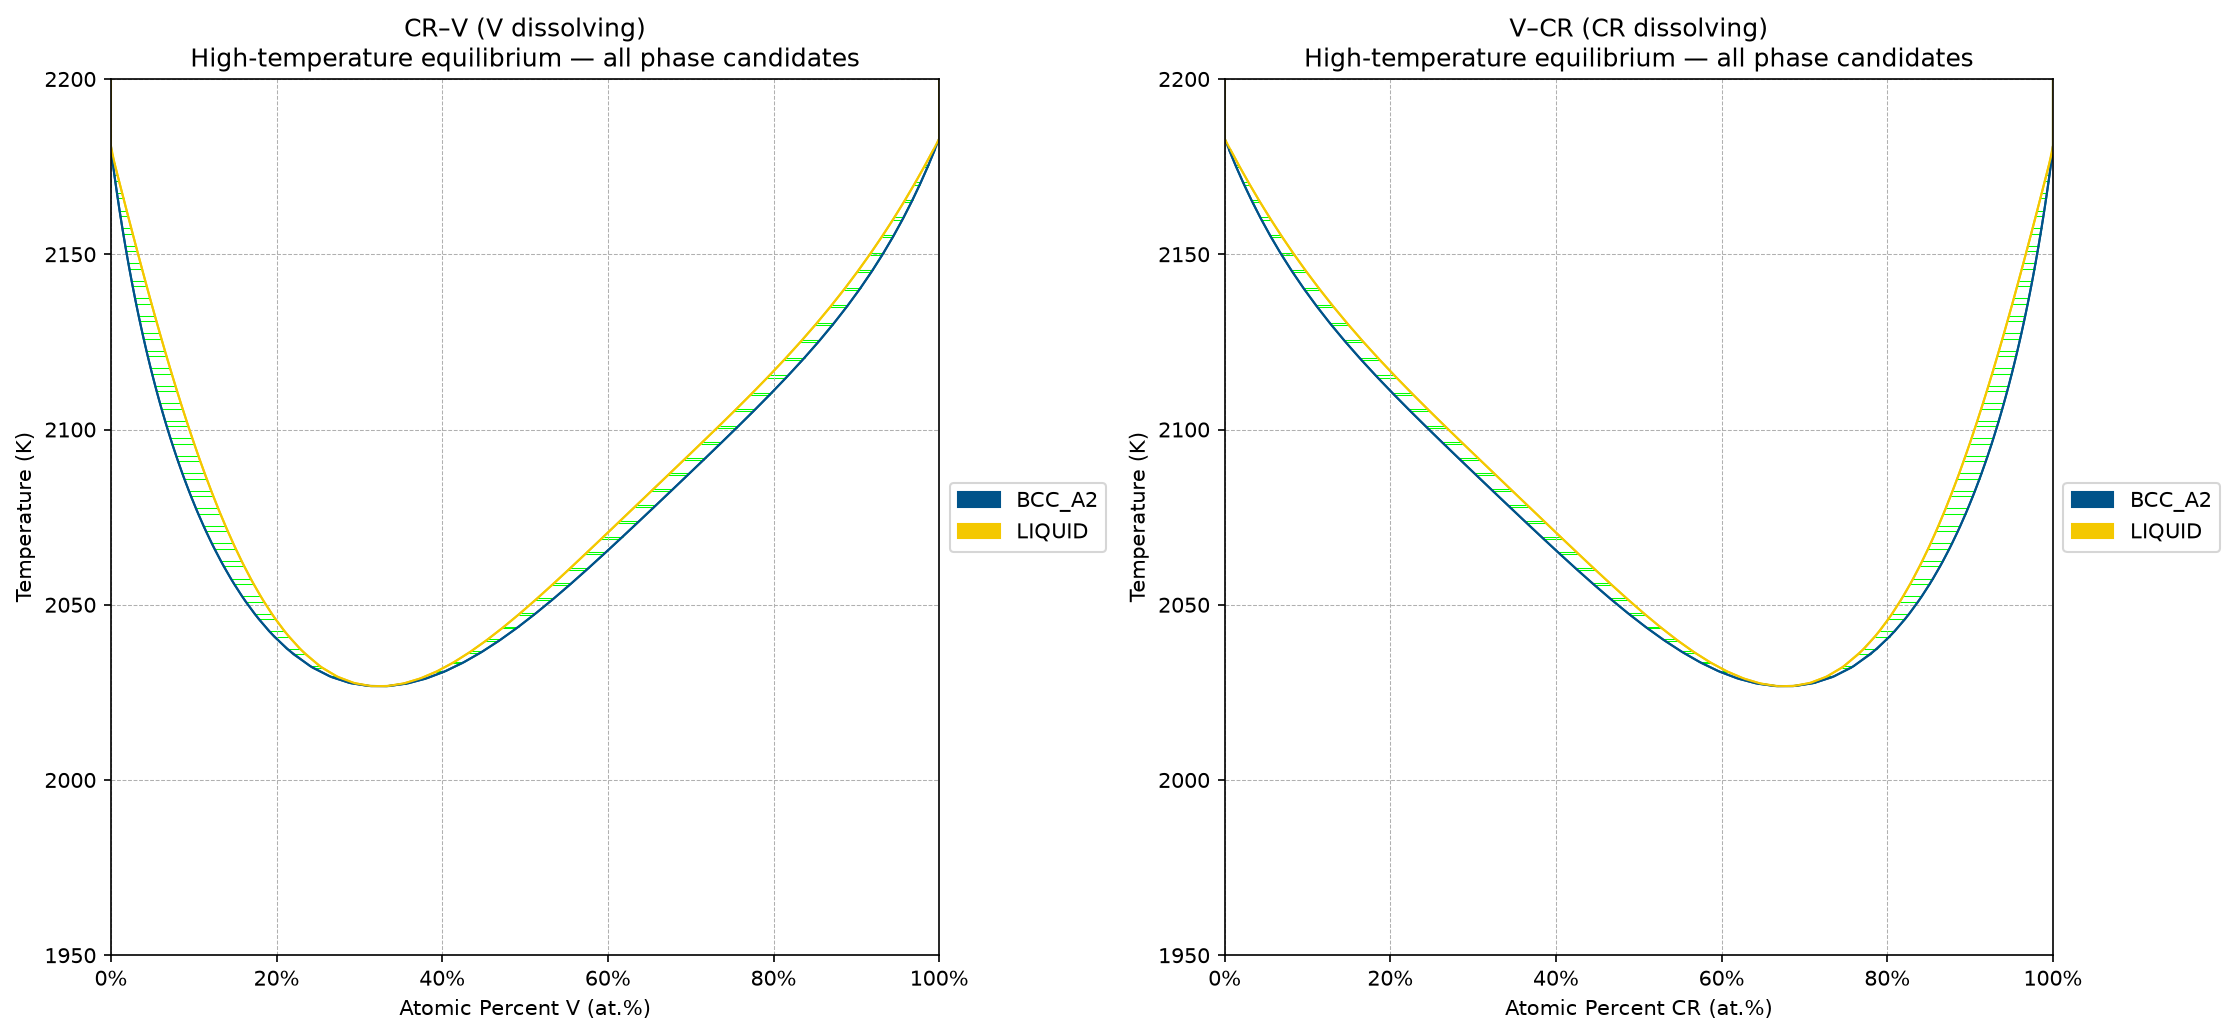

In [6]:
plot_diagram_pair(database, calculation_components, full_atomic_fraction_range, equilibrium_temperature_range, "High-temperature equilibrium — all phase candidates")

## 3. Focused system: 10–25 at.% equilibrium liquidus/solidus

Separate Cr–V and V–Cr diagrams show direct all-phase equilibrium solidus and liquidus boundaries. The tables identify the stable solid phase or phases immediately below solidus.

For each composition $X$, the boundaries are

$$T_{\mathrm{s}}=\min\{T:n_{\mathrm{L}}(T,X)>\varepsilon\}, quad T_{\mathrm{L}}=\min\{T:n_{\mathrm{L}}(T,X)\ge 1-\varepsilon\},$$

where $\varepsilon=10^{-6}$. The transition search is refined by bisection to $0.1\,\mathrm{K}$.

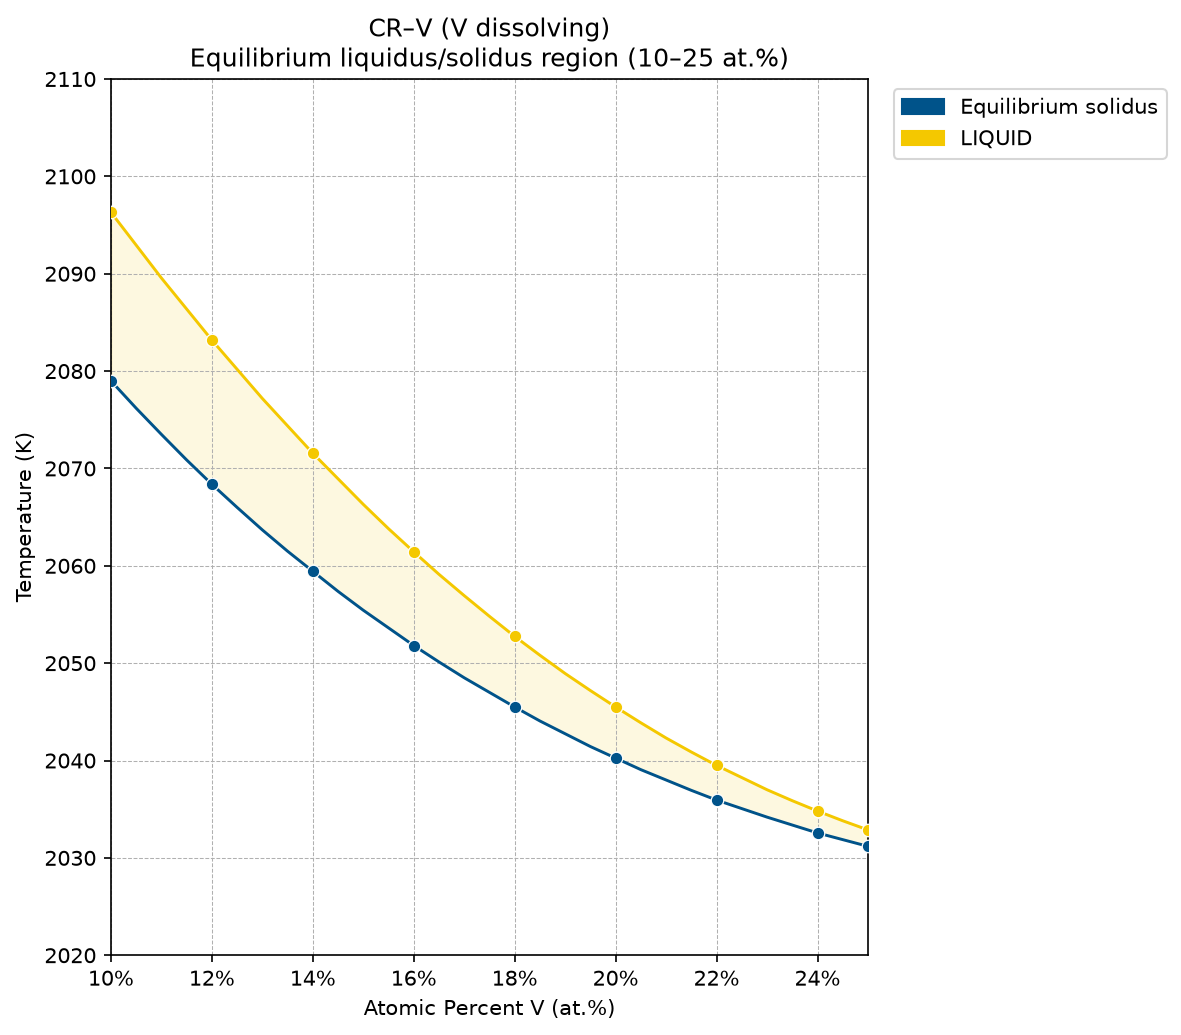

CR–V (V dissolving): selected equilibrium boundary temperatures


,V (at.%),Equilibrium solidus (K),Equilibrium liquidus (K),Stable solid phase(s) below solidus
0,10.0,2079.0,2096.3,BCC_A2
1,12.0,2068.4,2083.2,BCC_A2
2,14.0,2059.4,2071.6,BCC_A2
3,16.0,2051.8,2061.4,BCC_A2
4,18.0,2045.5,2052.8,BCC_A2
5,20.0,2040.2,2045.5,BCC_A2
6,22.0,2035.9,2039.5,BCC_A2
7,24.0,2032.6,2034.8,BCC_A2
8,25.0,2031.2,2032.9,BCC_A2


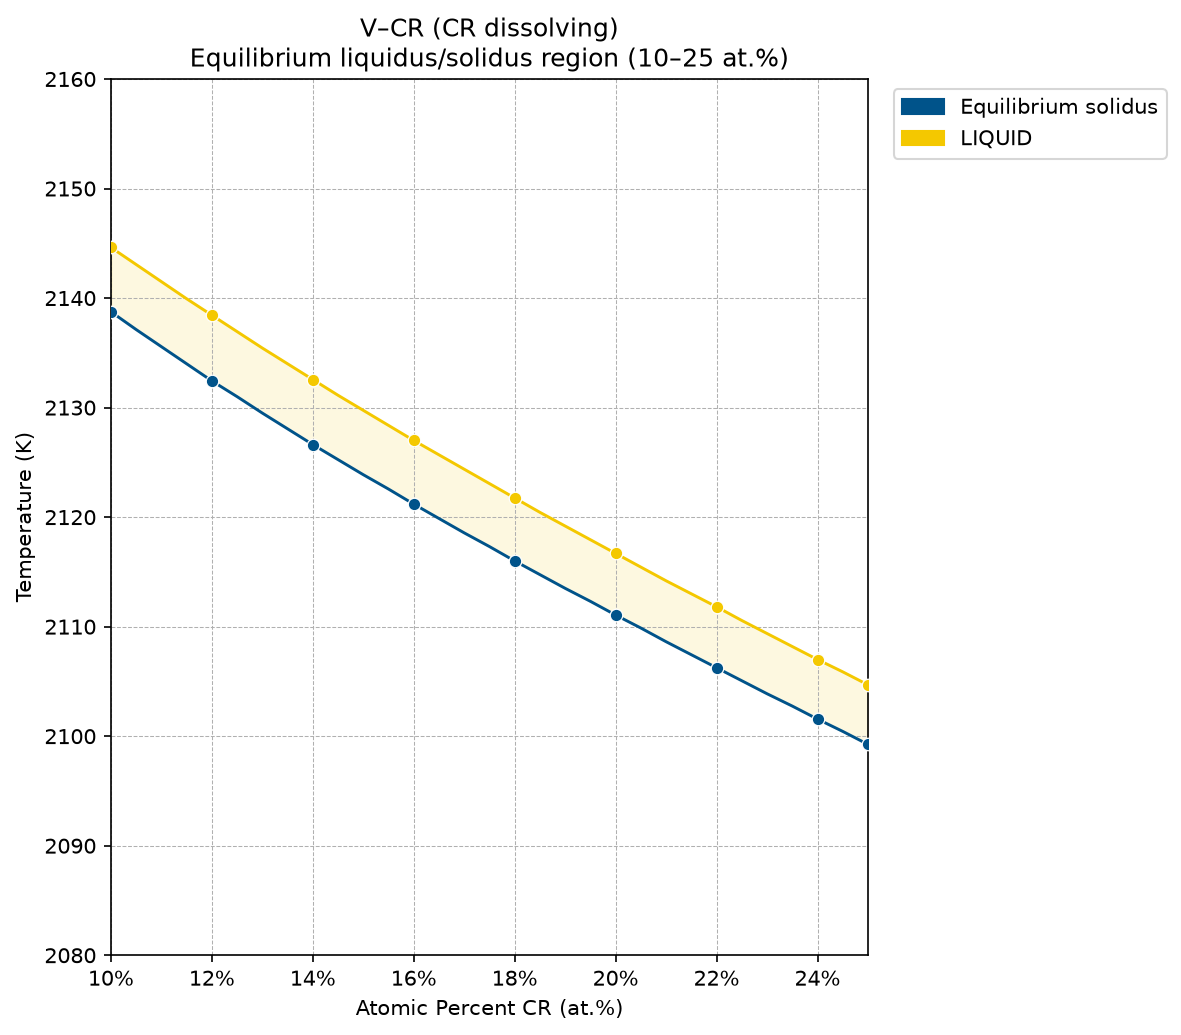

V–CR (CR dissolving): selected equilibrium boundary temperatures


,CR (at.%),Equilibrium solidus (K),Equilibrium liquidus (K),Stable solid phase(s) below solidus
0,10.0,2138.8,2144.6,BCC_A2
1,12.0,2132.4,2138.4,BCC_A2
2,14.0,2126.6,2132.6,BCC_A2
3,16.0,2121.2,2127.0,BCC_A2
4,18.0,2116.0,2121.8,BCC_A2
5,20.0,2111.1,2116.7,BCC_A2
6,22.0,2106.2,2111.8,BCC_A2
7,24.0,2101.6,2107.0,BCC_A2
8,25.0,2099.2,2104.7,BCC_A2


In [7]:
plot_focused_diagrams(database, calculation_components)